# 07 — Scenario Generation, Power-Curve Conversion, and Scenario Reduction

Split from `WindForecasting.ipynb`. Contents: validation residual analysis, dependence-preserving residual-trajectory bootstrap (1,000 wind-speed scenarios), conformal alignment of the scenario envelope, Vestas V90-3.0 MW power-curve conversion, day-ahead energy statistics, and K-means scenario reduction to K ∈ {20, 50, 100} with fidelity validation. Outputs are saved to `data/processed/` and `data/optimization_input/`.

**Prerequisite:** this notebook consumes Chronos-2 quantities computed in `03_Chronos2.ipynb` (`chronos_q50`, the calibrated quantiles, and the validation forecasts used to form `validation_residuals`). Run notebook 03 in the same kernel session first.

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
from rich.jupyter import display

# ============================================================
# PROJECT PATHS
# ============================================================

CURRENT_DIR = Path.cwd()

# Walk upward until a folder containing the raw wind dataset is found,
# so this notebook works from Data/Microgrid-Forecasting-Stochastic-
# Optimization/notebooks as well as from Data/notebooks. If the raw
# data is later copied into this repository's data/raw, the repository
# root is used automatically.
_candidates = [CURRENT_DIR, *CURRENT_DIR.parents]
PROJECT_ROOT = None
for candidate in _candidates:
    if (candidate / "data" / "raw" / "agregatenew.csv").exists():
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    # GitHub clone: raw data absent, derived inputs distributed
    for candidate in _candidates:
        if (candidate / "data" / "optimization_input"
                / "pgu_parameters.csv").exists():
            PROJECT_ROOT = candidate
            break
if PROJECT_ROOT is None:
    PROJECT_ROOT = CURRENT_DIR

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OPT_INPUT_DIR = PROJECT_ROOT / "data" / "optimization_input"
OPT_OUTPUT_DIR = PROJECT_ROOT / "data" / "optimization_output"
MODELS_DIR = PROJECT_ROOT / "models"
FIGURES_DIR = PROJECT_ROOT / "figures"

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data: {RAW_DIR}")

Project root: /Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data
Raw data: /Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data/data/raw


In [89]:
# ============================================================
# STEP 1: VALIDATION RESIDUAL TRAJECTORIES
# ============================================================

validation_residuals = (
    y_val_original
    -
    chronos_val_q50
)

print(
    "Validation residual trajectory shape:",
    validation_residuals.shape
)

print(
    "Mean residual:",
    validation_residuals.mean()
)

print(
    "Residual standard deviation:",
    validation_residuals.std()
)

Validation residual trajectory shape: (1233, 24)
Mean residual: 0.27346037777421756
Residual standard deviation: 3.582032405686816


In [90]:
# ============================================================
# STEP 2: RESIDUAL STATISTICS BY FORECAST HORIZON
# ============================================================

residual_statistics = pd.DataFrame({

    "Horizon": np.arange(
        1,
        FORECAST_HORIZON + 1
    ),

    "Mean Residual":
        validation_residuals.mean(axis=0),

    "Std Residual":
        validation_residuals.std(axis=0),

    "Median Residual":
        np.median(
            validation_residuals,
            axis=0
        )

})

display(
    residual_statistics.round(4)
)

,Horizon,Mean Residual,Std Residual,Median Residual
0,1,0.0489,1.2144,0.0229
1,2,0.0598,1.8417,0.0375
2,3,0.0678,2.3233,-0.0780
3,4,0.0949,2.7317,-0.0828
4,5,0.1344,3.0550,0.0090
5,6,0.1595,3.3019,-0.0645
6,7,0.1705,3.5170,-0.0030
7,8,0.1830,3.6829,0.0710
8,9,0.2074,3.7794,0.1120
9,10,0.2312,3.8550,-0.0062


In [91]:
# ============================================================
# STEP 3: CENTER RESIDUALS BY HORIZON
# ============================================================

residual_mean_by_horizon = (
    validation_residuals.mean(axis=0)
)

centered_residuals = (
    validation_residuals
    -
    residual_mean_by_horizon
)

print(
    "Centered residual mean by horizon:"
)

print(
    np.round(
        centered_residuals.mean(axis=0),
        6
    )
)

Centered residual mean by horizon:
[-0. -0. -0. -0.  0.  0. -0. -0.  0. -0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.]


In [92]:
# ============================================================
# STEP 4: RESIDUAL TRAJECTORY BOOTSTRAP
# ============================================================

def generate_residual_bootstrap_scenarios(
    point_forecast,
    residual_trajectories,
    n_scenarios=1000,
    random_seed=42
):

    rng = np.random.default_rng(
        random_seed
    )

    point_forecast = np.asarray(
        point_forecast
    )

    residual_trajectories = np.asarray(
        residual_trajectories
    )


    # Randomly sample complete residual trajectories
    sampled_indices = rng.choice(

        len(residual_trajectories),

        size=n_scenarios,

        replace=True

    )


    sampled_residuals = (

        residual_trajectories[
            sampled_indices
        ]

    )


    # Add sampled residual trajectories
    # to the 24-hour point forecast

    scenarios = (

        point_forecast[
            np.newaxis,
            :
        ]

        +

        sampled_residuals

    )


    # Physical constraint:
    # wind speed cannot be negative

    scenarios = np.clip(

        scenarios,

        a_min=0.0,

        a_max=None

    )


    return (
        scenarios,
        sampled_indices
    )

In [93]:
# ============================================================
# STEP 5: GENERATE SCENARIOS FOR ONE FORECAST ORIGIN
# ============================================================

FORECAST_ORIGIN = 0

N_SCENARIOS = 1000


point_forecast = (

    chronos_q50[
        FORECAST_ORIGIN
    ]

)


actual_trajectory = (

    y_test_original[
        FORECAST_ORIGIN
    ]

)


wind_speed_scenarios, sampled_indices = (

    generate_residual_bootstrap_scenarios(

        point_forecast=
            point_forecast,

        residual_trajectories=
            centered_residuals,

        n_scenarios=
            N_SCENARIOS,

        random_seed=
            42

    )

)


print(
    "Scenario matrix shape:",
    wind_speed_scenarios.shape
)

print(
    "Actual trajectory shape:",
    actual_trajectory.shape
)

Scenario matrix shape: (1000, 24)
Actual trajectory shape: (24,)


In [94]:
# ============================================================
# STEP 6: SCENARIO DISTRIBUTION STATISTICS
# ============================================================

scenario_mean = np.mean(
    wind_speed_scenarios,
    axis=0
)

scenario_median = np.median(
    wind_speed_scenarios,
    axis=0
)

scenario_q10 = np.quantile(
    wind_speed_scenarios,
    0.10,
    axis=0
)

scenario_q90 = np.quantile(
    wind_speed_scenarios,
    0.90,
    axis=0
)


scenario_statistics = pd.DataFrame({

    "Horizon":
        np.arange(
            1,
            FORECAST_HORIZON + 1
        ),

    "Actual":
        actual_trajectory,

    "Chronos P50":
        point_forecast,

    "Scenario Mean":
        scenario_mean,

    "Scenario Median":
        scenario_median,

    "Scenario P10":
        scenario_q10,

    "Scenario P90":
        scenario_q90

})


display(
    scenario_statistics.round(4)
)

,Horizon,Actual,Chronos P50,Scenario Mean,Scenario Median,Scenario P10,Scenario P90
0,1,4.8270,4.4580,4.4355,4.4416,3.0422,5.7479
1,2,5.7717,4.2579,4.2835,4.2029,2.1002,6.3786
2,3,5.6013,3.9555,4.0146,3.7898,1.5331,6.7745
3,4,5.0458,3.7042,3.8595,3.5530,0.7601,6.8492
4,5,4.2937,3.5709,3.7647,3.4992,0.2922,7.0065
5,6,2.5653,3.6104,3.8396,3.4249,0.0244,7.6744
6,7,2.4467,3.7506,4.0451,3.6656,0.0000,8.4663
7,8,4.2880,3.9227,4.1861,3.8430,0.0000,8.6812
8,9,6.7553,4.0945,4.4141,4.0301,0.0000,9.2939
9,10,9.5903,4.1803,4.4765,3.9626,0.0000,9.3636


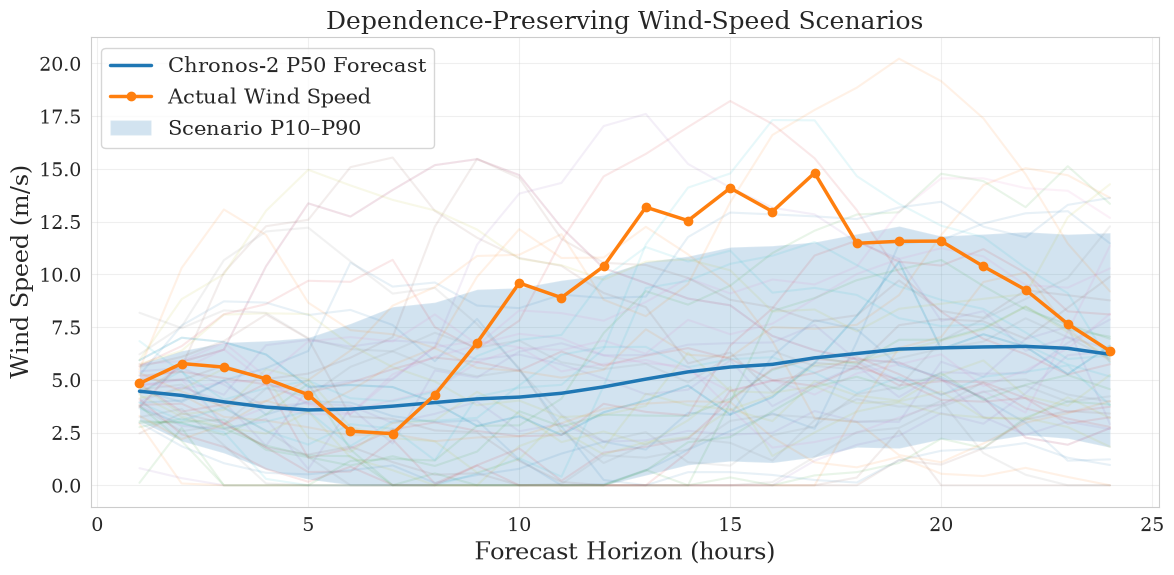

In [95]:
# ============================================================
# STEP 7: VISUALIZE SCENARIO TRAJECTORIES
# ============================================================

import matplotlib.pyplot as plt


hours = np.arange(
    1,
    FORECAST_HORIZON + 1
)


plt.figure(
    figsize=(12, 6)
)


# Plot only 50 scenarios for readability

for scenario in wind_speed_scenarios[:50]:

    plt.plot(
        hours,
        scenario,
        alpha=0.10
    )


plt.plot(
    hours,
    point_forecast,
    linewidth=2.5,
    label="Chronos-2 P50 Forecast"
)


plt.plot(
    hours,
    actual_trajectory,
    linewidth=2.5,
    marker="o",
    label="Actual Wind Speed"
)


plt.fill_between(

    hours,

    scenario_q10,

    scenario_q90,

    alpha=0.20,

    label="Scenario P10–P90"

)


plt.title(
    "Dependence-Preserving Wind-Speed Scenarios"
)

plt.xlabel(
    "Forecast Horizon (hours)"
)

plt.ylabel(
    "Wind Speed (m/s)"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

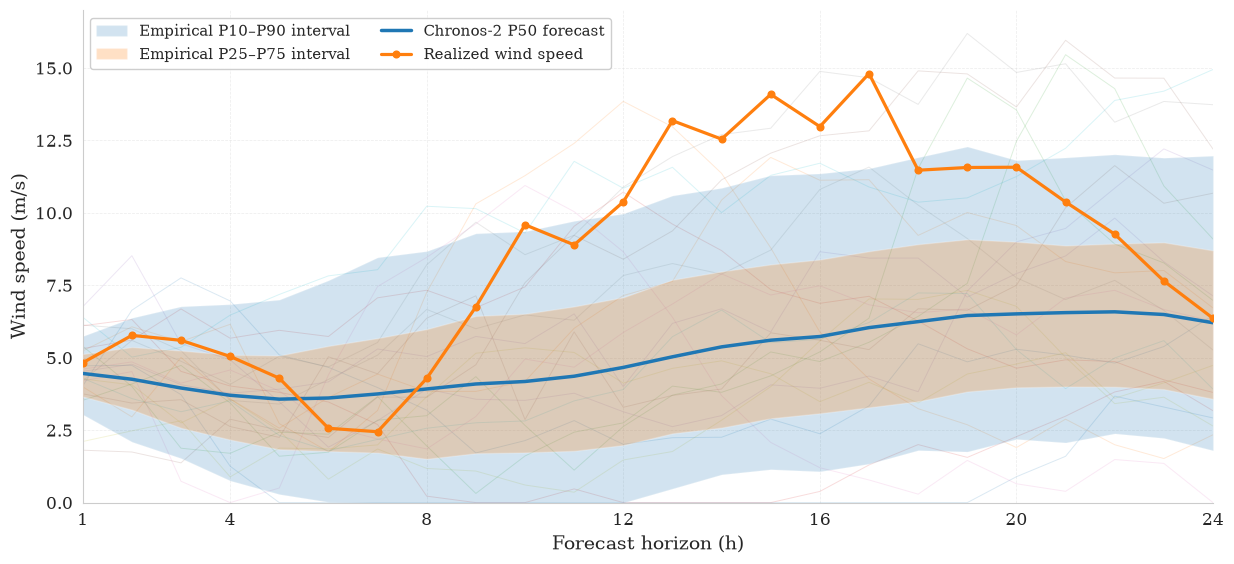

In [97]:
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# ============================================================
# INPUTS
# ============================================================

scenario_matrix = wind_speed_scenarios
chronos_p50 = point_forecast
actual_wind = actual_trajectory

# ============================================================
# VALIDATION
# ============================================================

scenario_matrix = np.asarray(
    scenario_matrix,
    dtype=float,
)

chronos_p50 = np.asarray(
    chronos_p50,
    dtype=float,
).reshape(-1)

actual_wind = np.asarray(
    actual_wind,
    dtype=float,
).reshape(-1)

if scenario_matrix.ndim != 2:
    raise ValueError(
        "scenario_matrix must be two-dimensional."
    )

if scenario_matrix.shape[1] != 24:
    raise ValueError(
        "scenario_matrix must contain 24 forecast horizons."
    )

if chronos_p50.shape[0] != 24:
    raise ValueError(
        "chronos_p50 must contain 24 values."
    )

if actual_wind.shape[0] != 24:
    raise ValueError(
        "actual_wind must contain 24 values."
    )

# ============================================================
# EMPIRICAL QUANTILES
# ============================================================

p10 = np.quantile(
    scenario_matrix,
    0.10,
    axis=0,
)

p25 = np.quantile(
    scenario_matrix,
    0.25,
    axis=0,
)

p75 = np.quantile(
    scenario_matrix,
    0.75,
    axis=0,
)

p90 = np.quantile(
    scenario_matrix,
    0.90,
    axis=0,
)

# ============================================================
# SELECT A REPRODUCIBLE SUBSAMPLE OF TRAJECTORIES
# ============================================================

rng = np.random.default_rng(
    seed=42
)

number_of_visible_scenarios = min(
    20,
    scenario_matrix.shape[0],
)

selected_indices = rng.choice(
    scenario_matrix.shape[0],
    size=number_of_visible_scenarios,
    replace=False,
)

selected_scenarios = scenario_matrix[
    selected_indices
]

# ============================================================
# PUBLICATION STYLE
# ============================================================

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 12,
        "axes.labelsize": 14,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 11,
        "axes.linewidth": 0.8,
        "savefig.dpi": 600,
    }
)

# ============================================================
# PLOT
# ============================================================

hours = np.arange(
    1,
    25,
)

fig, ax = plt.subplots(
    figsize=(12.5, 5.8)
)

# Individual scenario trajectories
for trajectory in selected_scenarios:
    ax.plot(
        hours,
        trajectory,
        linewidth=0.7,
        alpha=0.16,
        zorder=1,
    )

# P10–P90 interval
ax.fill_between(
    hours,
    p10,
    p90,
    alpha=0.20,
    label="Empirical P10–P90 interval",
    zorder=2,
)

# Optional P25–P75 inner band
ax.fill_between(
    hours,
    p25,
    p75,
    alpha=0.24,
    label="Empirical P25–P75 interval",
    zorder=3,
)

# Chronos-2 median forecast
ax.plot(
    hours,
    chronos_p50,
    linewidth=2.5,
    label="Chronos-2 P50 forecast",
    zorder=5,
)

# Realized wind speed
ax.plot(
    hours,
    actual_wind,
    linewidth=2.3,
    marker="o",
    markersize=4.8,
    label="Realized wind speed",
    zorder=6,
)

# ============================================================
# AXES
# ============================================================

ax.set_xlabel(
    "Forecast horizon (h)"
)

ax.set_ylabel(
    "Wind speed (m/s)"
)

ax.set_xlim(
    1,
    24,
)

ax.set_ylim(
    bottom=0
)

ax.set_xticks(
    [1, 4, 8, 12, 16, 20, 24]
)

ax.yaxis.set_major_locator(
    MultipleLocator(2.5)
)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.55,
    alpha=0.35,
)

ax.spines[
    "top"
].set_visible(False)

ax.spines[
    "right"
].set_visible(False)

# ============================================================
# LEGEND
# ============================================================

ax.legend(
    loc="upper left",
    frameon=True,
    framealpha=0.95,
    edgecolor="0.80",
    ncol=2,
)

# No title inside the figure:
# the caption already explains the content.

fig.tight_layout()

# ============================================================
# SAVE
# ============================================================

fig.savefig(
    "windSpeedScenarios_publication.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "windSpeedScenarios_publication.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()


In [98]:
# ============================================================
# STEP 8: COMPARE DEPENDENCE STRUCTURE
# ============================================================

validation_residual_correlation = (
    np.corrcoef(
        centered_residuals,
        rowvar=False
    )
)


scenario_deviation = (

    wind_speed_scenarios

    -

    point_forecast[
        np.newaxis,
        :
    ]

)


scenario_residual_correlation = (

    np.corrcoef(
        scenario_deviation,
        rowvar=False
    )

)


correlation_difference = np.mean(

    np.abs(

        validation_residual_correlation

        -

        scenario_residual_correlation

    )

)


print(
    "Mean absolute correlation-matrix difference:"
)

print(
    f"{correlation_difference:.6f}"
)

Mean absolute correlation-matrix difference:
0.030377


In [99]:
# ============================================================
# STEP 9: CALCULATE EMPIRICAL RESIDUAL QUANTILES
# ============================================================

residual_q10 = np.quantile(
    centered_residuals,
    0.10,
    axis=0
)

residual_q90 = np.quantile(
    centered_residuals,
    0.90,
    axis=0
)

print("Residual Q10 shape:", residual_q10.shape)
print("Residual Q90 shape:", residual_q90.shape)

Residual Q10 shape: (24,)
Residual Q90 shape: (24,)


In [100]:
# ============================================================
# STEP 10: CALIBRATED TARGET DEVIATIONS AROUND P50
# ============================================================

calibrated_lower = chronos_q10_calibrated[
    FORECAST_ORIGIN
]

calibrated_upper = chronos_q90_calibrated[
    FORECAST_ORIGIN
]

point_forecast = chronos_q50[
    FORECAST_ORIGIN
]


target_lower_deviation = (
    calibrated_lower
    -
    point_forecast
)

target_upper_deviation = (
    calibrated_upper
    -
    point_forecast
)


print("Target lower deviation shape:",
      target_lower_deviation.shape)

print("Target upper deviation shape:",
      target_upper_deviation.shape)

Target lower deviation shape: (24,)
Target upper deviation shape: (24,)


In [101]:
# ============================================================
# STEP 11: ASYMMETRIC HORIZON-WISE SCALING FACTORS
# ============================================================

EPSILON = 1e-8


lower_scale = (
    target_lower_deviation
    /
    (residual_q10 + EPSILON)
)


upper_scale = (
    target_upper_deviation
    /
    (residual_q90 + EPSILON)
)


# Prevent negative scaling factors
lower_scale = np.maximum(
    lower_scale,
    0.0
)

upper_scale = np.maximum(
    upper_scale,
    0.0
)


scaling_factors_df = pd.DataFrame({

    "Horizon":
        np.arange(
            1,
            FORECAST_HORIZON + 1
        ),

    "Residual Q10":
        residual_q10,

    "Residual Q90":
        residual_q90,

    "Target Lower Deviation":
        target_lower_deviation,

    "Target Upper Deviation":
        target_upper_deviation,

    "Lower Scale":
        lower_scale,

    "Upper Scale":
        upper_scale

})


display(
    scaling_factors_df.round(4)
)

,Horizon,Residual Q10,Residual Q90,Target Lower Deviation,Target Upper Deviation,Lower Scale,Upper Scale
0,1,-1.4335,1.4211,-1.1847,1.5952,0.8265,1.1225
1,2,-2.1837,2.1624,-1.6970,2.1579,0.7771,0.9980
2,3,-2.6174,2.8132,-1.7825,2.4417,0.6810,0.8679
3,4,-3.1099,3.2648,-1.9839,2.7146,0.6379,0.8315
4,5,-3.3590,3.6612,-2.0301,2.9762,0.6044,0.8129
5,6,-3.6670,4.0964,-2.2302,3.2706,0.6082,0.7984
6,7,-3.9343,4.4168,-2.5123,3.5803,0.6386,0.8106
7,8,-4.2600,4.7196,-2.6392,3.9735,0.6195,0.8419
8,9,-4.4154,4.7645,-2.8804,4.3017,0.6524,0.9029
9,10,-4.6160,4.8698,-2.8098,4.6627,0.6087,0.9575


In [102]:
# ============================================================
# STEP 12: SCALE COMPLETE RESIDUAL TRAJECTORIES
# ============================================================

def scale_residual_trajectories_asymmetric(
    residual_trajectories,
    lower_scale,
    upper_scale
):

    scaled_residuals = np.zeros_like(
        residual_trajectories
    )


    # Negative residuals
    negative_mask = (
        residual_trajectories < 0
    )


    # Positive residuals
    positive_mask = (
        residual_trajectories >= 0
    )


    scaled_residuals = np.where(

        negative_mask,

        residual_trajectories
        *
        lower_scale[np.newaxis, :],

        residual_trajectories
        *
        upper_scale[np.newaxis, :]

    )


    return scaled_residuals

In [103]:
# ============================================================
# STEP 13: GENERATE CONFORMALLY ALIGNED SCENARIOS
# ============================================================

rng = np.random.default_rng(42)


sampled_indices = rng.choice(

    len(centered_residuals),

    size=N_SCENARIOS,

    replace=True

)


sampled_residuals = (

    centered_residuals[
        sampled_indices
    ]

)


scaled_sampled_residuals = (

    scale_residual_trajectories_asymmetric(

        sampled_residuals,

        lower_scale,

        upper_scale

    )

)


calibrated_wind_scenarios = (

    point_forecast[
        np.newaxis,
        :
    ]

    +

    scaled_sampled_residuals

)


# Physical constraint

calibrated_wind_scenarios = np.clip(

    calibrated_wind_scenarios,

    a_min=0.0,

    a_max=None

)


print(
    "Calibrated scenario shape:",
    calibrated_wind_scenarios.shape
)

Calibrated scenario shape: (1000, 24)


In [104]:
# ============================================================
# STEP 14: SCENARIO CALIBRATION CHECK
# ============================================================

generated_q10 = np.quantile(

    calibrated_wind_scenarios,

    0.10,

    axis=0

)


generated_q50 = np.quantile(

    calibrated_wind_scenarios,

    0.50,

    axis=0

)


generated_q90 = np.quantile(

    calibrated_wind_scenarios,

    0.90,

    axis=0

)


scenario_calibration_check = pd.DataFrame({

    "Horizon":
        np.arange(
            1,
            FORECAST_HORIZON + 1
        ),

    "Target Calibrated Q10":
        calibrated_lower,

    "Generated Scenario Q10":
        generated_q10,

    "Chronos P50":
        point_forecast,

    "Generated Scenario P50":
        generated_q50,

    "Target Calibrated Q90":
        calibrated_upper,

    "Generated Scenario Q90":
        generated_q90

})


display(
    scenario_calibration_check.round(4)
)

,Horizon,Target Calibrated Q10,Generated Scenario Q10,Chronos P50,Generated Scenario P50,Target Calibrated Q90,Generated Scenario Q90
0,1,3.2732,3.2879,4.4580,4.4444,6.0532,5.9060
1,2,2.5610,2.5812,4.2579,4.2152,6.4159,6.3742
2,3,2.1730,2.3058,3.9555,3.8426,6.3972,6.4022
3,4,1.7203,1.8261,3.7042,3.6078,6.4188,6.3192
4,5,1.5409,1.5894,3.5709,3.5276,6.5472,6.3637
5,6,1.3802,1.4291,3.6104,3.4976,6.8809,6.8551
6,7,1.2384,1.1168,3.7506,3.6964,7.3309,7.5731
7,8,1.2835,1.2918,3.9227,3.8733,7.8962,7.9290
8,9,1.2141,1.2425,4.0945,4.0525,8.3962,8.7888
9,10,1.3705,1.3938,4.1803,4.0478,8.8430,9.1432


In [105]:
# ============================================================
# STEP 15: QUANTILE ALIGNMENT ERROR
# ============================================================

q10_alignment_error = np.mean(

    np.abs(

        generated_q10

        -

        calibrated_lower

    )

)


q90_alignment_error = np.mean(

    np.abs(

        generated_q90

        -

        calibrated_upper

    )

)


print(
    "Mean absolute Q10 alignment error:",
    f"{q10_alignment_error:.4f} m/s"
)

print(
    "Mean absolute Q90 alignment error:",
    f"{q90_alignment_error:.4f} m/s"
)

Mean absolute Q10 alignment error: 0.0902 m/s
Mean absolute Q90 alignment error: 0.2172 m/s


In [106]:
# ============================================================
# STEP 16: DEPENDENCE PRESERVATION AFTER CALIBRATION
# ============================================================

calibrated_scenario_deviation = (

    calibrated_wind_scenarios

    -

    point_forecast[
        np.newaxis,
        :
    ]

)


calibrated_scenario_correlation = np.corrcoef(

    calibrated_scenario_deviation,

    rowvar=False

)


calibrated_correlation_difference = np.mean(

    np.abs(

        validation_residual_correlation

        -

        calibrated_scenario_correlation

    )

)


print(
    "Mean absolute correlation-matrix difference "
    "after conformal alignment:"
)

print(
    f"{calibrated_correlation_difference:.6f}"
)

Mean absolute correlation-matrix difference after conformal alignment:
0.030695


Use the Vestas V90-3.0 MW to remain consistent with your original manuscript. The turbine has 3,000 kW rated capacity; Vestas documentation evaluates its production curve over 0–25 m/s and identifies 25 m/s as its original cut-out setting. Public technical summaries report approximately 4 m/s cut-in and 15 m/s rated wind speed.
A caution for the manuscript: the exact manufacturer lookup table is not fully disclosed in the current official material. Therefore, describe the implementation as a:
manufacturer-parameterized V90-3.0 MW power-curve approximation
rather than claiming that it is the exact proprietary manufacturer curve.


In [107]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# VESTAS V90-3.0 MW TURBINE PARAMETERS
# ============================================================

TURBINE_NAME = "Vestas V90-3.0 MW"

RATED_POWER_KW = 3000.0

CUT_IN_SPEED = 4.0       # m/s
RATED_SPEED = 15.0       # m/s
CUT_OUT_SPEED = 25.0     # m/s

TIME_STEP_HOURS = 1.0

print(TURBINE_NAME)
print(f"Rated power: {RATED_POWER_KW:.0f} kW")
print(f"Cut-in speed: {CUT_IN_SPEED:.1f} m/s")
print(f"Rated speed: {RATED_SPEED:.1f} m/s")
print(f"Cut-out speed: {CUT_OUT_SPEED:.1f} m/s")

Vestas V90-3.0 MW
Rated power: 3000 kW
Cut-in speed: 4.0 m/s
Rated speed: 15.0 m/s
Cut-out speed: 25.0 m/s


In [108]:
# ============================================================
# OPTIONAL WIND-SPEED HUB-HEIGHT CORRECTION
# ============================================================

def adjust_wind_speed_to_hub_height(
    wind_speed,
    measurement_height,
    hub_height=80.0,
    shear_exponent=0.14
):
    """
    Adjust wind speed from the measurement height to turbine
    hub height using the power-law wind profile.

    Parameters
    ----------
    wind_speed : array-like
        Wind speed at measurement height in m/s.
    measurement_height : float
        Sensor height in meters.
    hub_height : float
        Turbine hub height in meters.
    shear_exponent : float
        Site-specific wind shear exponent.

    Returns
    -------
    np.ndarray
        Wind speed estimated at hub height.
    """

    if measurement_height <= 0 or hub_height <= 0:
        raise ValueError("Heights must be greater than zero.")

    wind_speed = np.asarray(wind_speed, dtype=float)

    return wind_speed * (
        hub_height / measurement_height
    ) ** shear_exponent

3. Define the power-curve approximation
This function uses:
zero generation below cut-in;
a cubic aerodynamic region between cut-in and rated speed;
3 MW output from rated speed to cut-out;
zero output at and above cut-out.


In [109]:
# ============================================================
# V90-3.0 MW PARAMETERIZED POWER CURVE
# ============================================================

def wind_speed_to_power_v90(
    wind_speed,
    rated_power_kw=RATED_POWER_KW,
    cut_in=CUT_IN_SPEED,
    rated_speed=RATED_SPEED,
    cut_out=CUT_OUT_SPEED
):
    """
    Convert wind speed to electrical power using a transparent
    parameterized approximation of the Vestas V90-3.0 MW
    operating curve.

    Parameters
    ----------
    wind_speed : array-like
        Wind speed in m/s.
    rated_power_kw : float
        Rated turbine power in kW.
    cut_in : float
        Cut-in wind speed in m/s.
    rated_speed : float
        Wind speed at which rated power is reached.
    cut_out : float
        Cut-out wind speed in m/s.

    Returns
    -------
    np.ndarray
        Gross electrical power in kW.
    """

    wind_speed = np.asarray(
        wind_speed,
        dtype=float
    )

    if not (
        0 <= cut_in < rated_speed < cut_out
    ):
        raise ValueError(
            "Required relationship: "
            "0 <= cut_in < rated_speed < cut_out."
        )

    power_kw = np.zeros_like(
        wind_speed,
        dtype=float
    )

    # Region 1:
    # Cut-in <= wind speed < rated speed

    partial_load_mask = (
        (wind_speed >= cut_in)
        &
        (wind_speed < rated_speed)
    )

    numerator = (
        wind_speed[partial_load_mask] ** 3
        -
        cut_in ** 3
    )

    denominator = (
        rated_speed ** 3
        -
        cut_in ** 3
    )

    power_kw[partial_load_mask] = (
        rated_power_kw
        *
        numerator
        /
        denominator
    )

    # Region 2:
    # Rated speed <= wind speed < cut-out

    rated_power_mask = (
        (wind_speed >= rated_speed)
        &
        (wind_speed < cut_out)
    )

    power_kw[rated_power_mask] = (
        rated_power_kw
    )

    # Physical and numerical limits

    power_kw = np.clip(
        power_kw,
        a_min=0.0,
        a_max=rated_power_kw
    )

    return power_kw

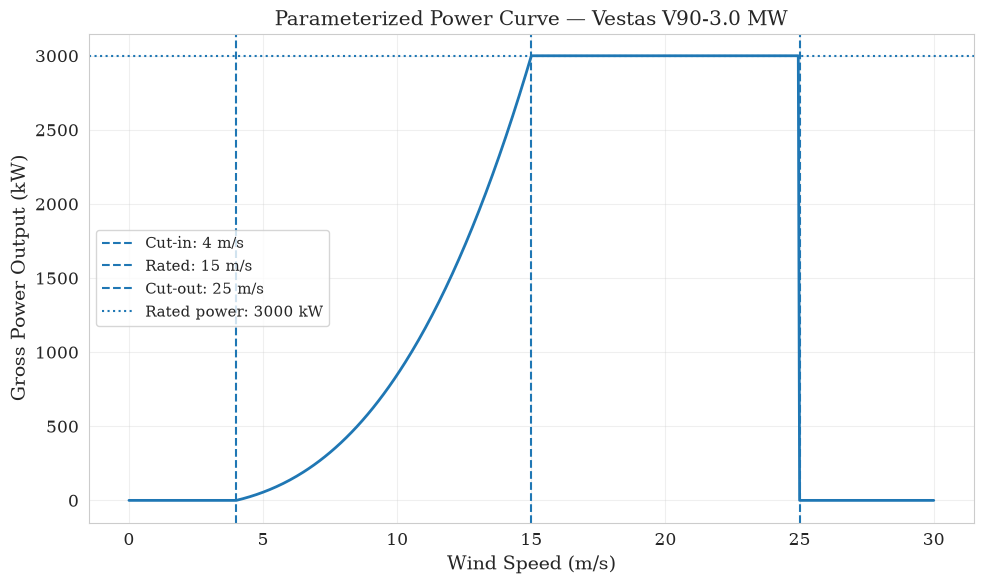

In [110]:
# ============================================================
# POWER-CURVE VISUALIZATION
# ============================================================

curve_wind_speed = np.linspace(
    0,
    30,
    601
)

curve_power_kw = wind_speed_to_power_v90(
    curve_wind_speed
)

plt.figure(figsize=(10, 6))

plt.plot(
    curve_wind_speed,
    curve_power_kw,
    linewidth=2
)

plt.axvline(
    CUT_IN_SPEED,
    linestyle="--",
    label=f"Cut-in: {CUT_IN_SPEED:.0f} m/s"
)

plt.axvline(
    RATED_SPEED,
    linestyle="--",
    label=f"Rated: {RATED_SPEED:.0f} m/s"
)

plt.axvline(
    CUT_OUT_SPEED,
    linestyle="--",
    label=f"Cut-out: {CUT_OUT_SPEED:.0f} m/s"
)

plt.axhline(
    RATED_POWER_KW,
    linestyle=":",
    label=f"Rated power: {RATED_POWER_KW:.0f} kW"
)

plt.title(
    "Parameterized Power Curve — Vestas V90-3.0 MW"
)

plt.xlabel("Wind Speed (m/s)")
plt.ylabel("Gross Power Output (kW)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [111]:
# ============================================================
# POWER-CURVE SANITY CHECK
# ============================================================

test_wind_speeds = np.array([
    0.0,
    3.9,
    4.0,
    5.0,
    8.0,
    10.0,
    12.0,
    14.0,
    15.0,
    20.0,
    24.9,
    25.0,
    30.0
])

test_power = wind_speed_to_power_v90(
    test_wind_speeds
)

power_curve_check = pd.DataFrame({
    "Wind Speed (m/s)": test_wind_speeds,
    "Power (kW)": test_power,
    "Capacity Factor": (
        test_power / RATED_POWER_KW
    )
})

display(
    power_curve_check.round(4)
)

,Wind Speed (m/s),Power (kW),Capacity Factor
0,0.0,0.0000,0.0000
1,3.9,0.0000,0.0000
2,4.0,0.0000,0.0000
3,5.0,55.2703,0.0184
4,8.0,405.9197,0.1353
5,10.0,848.0822,0.2827
6,12.0,1507.7016,0.5026
7,14.0,2428.2694,0.8094
8,15.0,3000.0000,1.0000
9,20.0,3000.0000,1.0000


In [112]:
# ============================================================
# CONVERT SCENARIO WIND SPEED TO POWER
# ============================================================

wind_power_scenarios_kw = wind_speed_to_power_v90(
    calibrated_wind_scenarios
)

print(
    "Wind-speed scenario shape:",
    calibrated_wind_scenarios.shape
)

print(
    "Wind-power scenario shape:",
    wind_power_scenarios_kw.shape
)

print(
    "Minimum scenario power:",
    wind_power_scenarios_kw.min(),
    "kW"
)

print(
    "Maximum scenario power:",
    wind_power_scenarios_kw.max(),
    "kW"
)

Wind-speed scenario shape: (1000, 24)
Wind-power scenario shape: (1000, 24)
Minimum scenario power: 0.0 kW
Maximum scenario power: 3000.0 kW


In [113]:
# ============================================================
# POINT FORECAST AND ACTUAL POWER
# ============================================================

forecast_power_kw = wind_speed_to_power_v90(
    point_forecast
)

actual_power_kw = wind_speed_to_power_v90(
    actual_trajectory
)

calibrated_lower_power_kw = wind_speed_to_power_v90(
    calibrated_lower
)

calibrated_upper_power_kw = wind_speed_to_power_v90(
    calibrated_upper
)

print("Forecast power shape:", forecast_power_kw.shape)
print("Actual power shape:", actual_power_kw.shape)

Forecast power shape: (24,)
Actual power shape: (24,)


In [114]:
# ============================================================
# EMPIRICAL POWER-SCENARIO DISTRIBUTION
# ============================================================

power_scenario_mean_kw = np.mean(
    wind_power_scenarios_kw,
    axis=0
)

power_scenario_median_kw = np.median(
    wind_power_scenarios_kw,
    axis=0
)

power_scenario_q10_kw = np.quantile(
    wind_power_scenarios_kw,
    0.10,
    axis=0
)

power_scenario_q90_kw = np.quantile(
    wind_power_scenarios_kw,
    0.90,
    axis=0
)

power_scenario_std_kw = np.std(
    wind_power_scenarios_kw,
    axis=0
)

In [115]:
power_scenario_statistics = pd.DataFrame({

    "Horizon":
        np.arange(
            1,
            FORECAST_HORIZON + 1
        ),

    "Actual Wind Speed (m/s)":
        actual_trajectory,

    "Forecast Wind Speed P50 (m/s)":
        point_forecast,

    "Actual Power (kW)":
        actual_power_kw,

    "Forecast Power (kW)":
        forecast_power_kw,

    "Scenario Mean Power (kW)":
        power_scenario_mean_kw,

    "Scenario Median Power (kW)":
        power_scenario_median_kw,

    "Scenario P10 Power (kW)":
        power_scenario_q10_kw,

    "Scenario P90 Power (kW)":
        power_scenario_q90_kw,

    "Scenario Std Power (kW)":
        power_scenario_std_kw

})

display(
    power_scenario_statistics.round(3)
)

,Horizon,Actual Wind Speed (m/s),Forecast Wind Speed P50 (m/s),Actual Power (kW),Forecast Power (kW),Scenario Mean Power (kW),Scenario Median Power (kW),Scenario P10 Power (kW),Scenario P90 Power (kW),Scenario Std Power (kW)
0,1,4.827,4.458,43.916,22.285,51.957,21.555,0.0,128.666,80.979
1,2,5.772,4.258,116.219,11.957,66.347,9.871,0.0,176.675,141.270
2,3,5.601,3.955,101.246,0.000,64.334,0.000,0.0,179.777,158.199
3,4,5.046,3.704,58.414,0.000,69.318,0.000,0.0,170.648,183.223
4,5,4.294,3.571,13.733,0.000,74.482,0.000,0.0,175.521,223.607
5,6,2.565,3.610,0.000,0.000,84.465,0.000,0.0,233.890,237.025
6,7,2.447,3.751,0.000,0.000,107.324,0.000,0.0,335.549,266.685
7,8,4.288,3.923,13.449,0.000,131.264,0.000,0.0,393.682,308.368
8,9,6.755,4.094,221.332,4.207,178.317,2.311,0.0,557.120,398.435
9,10,9.590,4.180,741.226,8.200,209.208,2.104,0.0,634.566,468.516


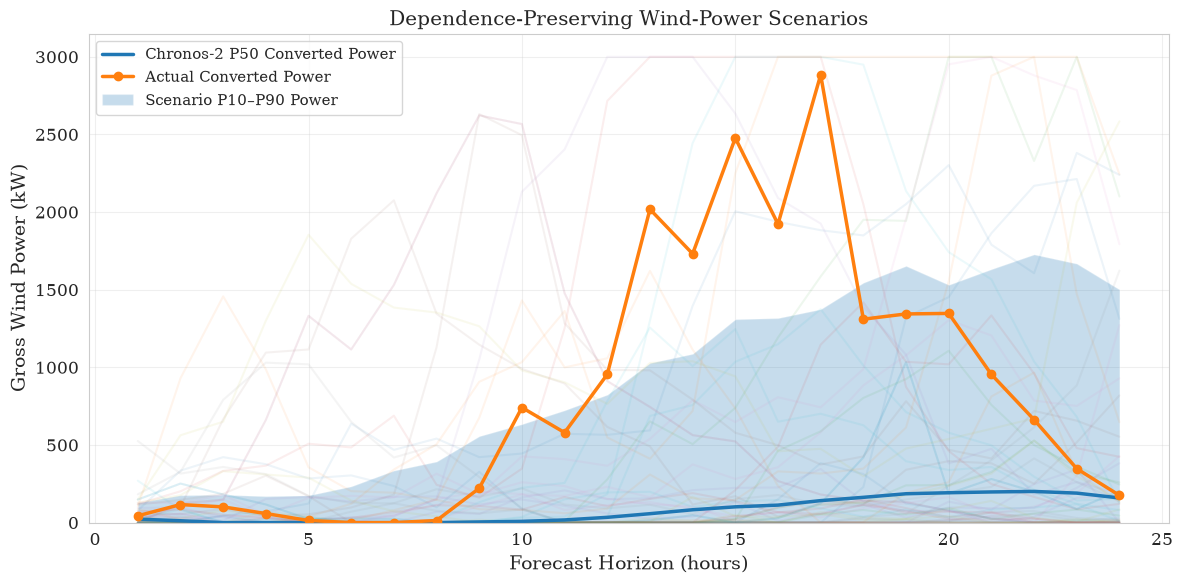

In [116]:
# ============================================================
# VISUALIZE WIND-POWER SCENARIOS
# ============================================================

hours = np.arange(
    1,
    FORECAST_HORIZON + 1
)

plt.figure(figsize=(12, 6))

# Plot a subset for readability

for scenario in wind_power_scenarios_kw[:50]:

    plt.plot(
        hours,
        scenario,
        alpha=0.08
    )

plt.plot(
    hours,
    forecast_power_kw,
    linewidth=2.5,
    label="Chronos-2 P50 Converted Power"
)

plt.plot(
    hours,
    actual_power_kw,
    linewidth=2.5,
    marker="o",
    label="Actual Converted Power"
)

plt.fill_between(
    hours,
    power_scenario_q10_kw,
    power_scenario_q90_kw,
    alpha=0.25,
    label="Scenario P10–P90 Power"
)

plt.title(
    "Dependence-Preserving Wind-Power Scenarios"
)

plt.xlabel("Forecast Horizon (hours)")
plt.ylabel("Gross Wind Power (kW)")

plt.ylim(
    0,
    RATED_POWER_KW * 1.05
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [120]:
locals().keys()

dict_keys(['__name__', '__doc__', '__package__', '__loader__', '__spec__', '__builtin__', '__builtins__', '_ih', '_oh', '_dh', 'In', 'Out', 'get_ipython', 'exit', 'quit', 'open', '_', '__', '___', '__session__', 'plt', '_pydevd_bundle', '_i', '_ii', '_iii', '_i1', 'mdates', 'fig', 'ax', 'pydev_jupyter_vars', '_i2', 'pd', 'np', '_i3', 'Path', 'display', 'CURRENT_DIR', 'PROJECT_ROOT', 'RAW_DIR', 'PROCESSED_DIR', 'OPT_INPUT_DIR', 'OPT_OUTPUT_DIR', 'MODELS_DIR', 'FIGURES_DIR', '_i4', 'WIND_FILE', 'OPERATIONAL_FILE', 'wind_df', 'operational_df', '_i5', 'sns', 'df', '_i6', '_i7', '_i8', 'time_difference', '_i9', '_i10', 'dates', 'wind_speed', 'plot_df', '_i11', 'plot_acf', 'plot_pacf', 'adfuller', 'STL', 'monthly_stats', 'hourly_pattern', 'adf_result', 'key', 'value', 'stl', 'result', '_i12', 'annotations', 'MultipleLocator', '_i13', '_i14', '_i15', '_i16', 'n', 'train_end', 'val_end', 'train_df', 'val_df', 'test_df', 'mean_absolute_error', 'mean_squared_error', 'r2_score', 'y_true', 'y_pred

In [121]:
power_scenarios = wind_power_scenarios_kw
p50_power = forecast_power_kw
actual_power = actual_power_kw

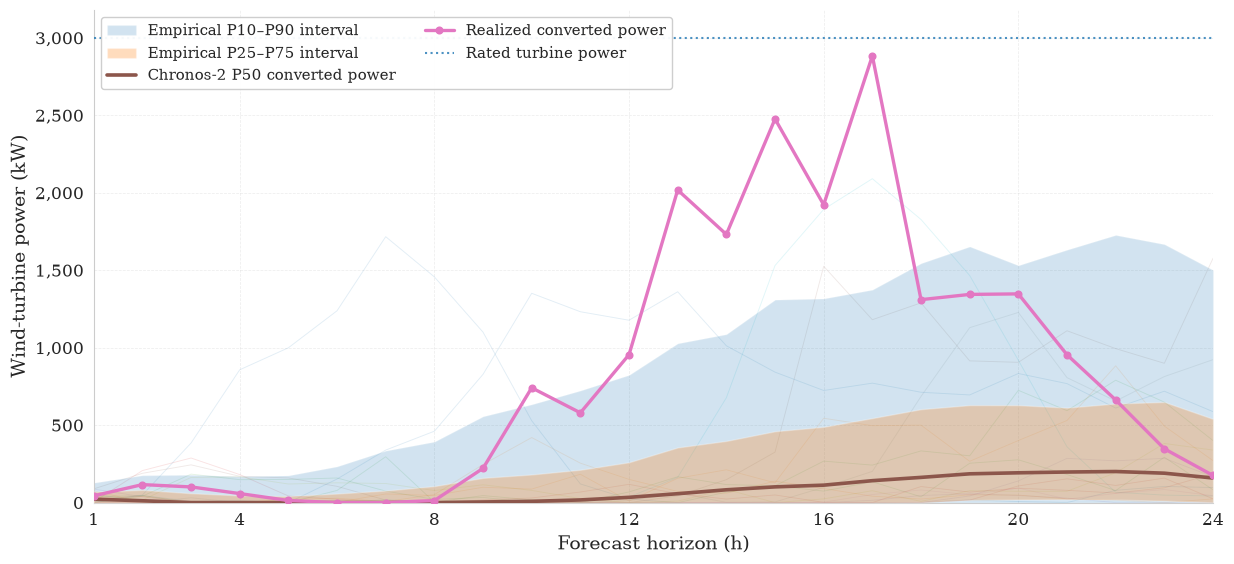

In [122]:
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, StrMethodFormatter


# ============================================================
# EXPECTED INPUTS
# ============================================================
# power_scenarios : array, shape (n_scenarios, 24)
# p50_power       : array, shape (24,)
# actual_power    : array, shape (24,)


# ============================================================
# VALIDATE INPUTS
# ============================================================

power_scenarios = np.asarray(
    power_scenarios,
    dtype=float,
)

p50_power = np.asarray(
    p50_power,
    dtype=float,
).reshape(-1)

actual_power = np.asarray(
    actual_power,
    dtype=float,
).reshape(-1)

if power_scenarios.ndim != 2:
    raise ValueError(
        "power_scenarios must be a two-dimensional array."
    )

if power_scenarios.shape[1] != 24:
    raise ValueError(
        "power_scenarios must contain 24 forecast horizons."
    )

if p50_power.shape[0] != 24:
    raise ValueError(
        "p50_power must contain 24 values."
    )

if actual_power.shape[0] != 24:
    raise ValueError(
        "actual_power must contain 24 values."
    )

if not np.isfinite(power_scenarios).all():
    raise ValueError(
        "power_scenarios contains NaN or infinite values."
    )


# ============================================================
# TURBINE SETTINGS
# ============================================================

RATED_POWER_KW = 3000.0


# ============================================================
# EMPIRICAL QUANTILES
# ============================================================

p10 = np.quantile(
    power_scenarios,
    0.10,
    axis=0,
)

p25 = np.quantile(
    power_scenarios,
    0.25,
    axis=0,
)

p75 = np.quantile(
    power_scenarios,
    0.75,
    axis=0,
)

p90 = np.quantile(
    power_scenarios,
    0.90,
    axis=0,
)


# ============================================================
# REPRODUCIBLE TRAJECTORY SUBSAMPLE
# ============================================================

rng = np.random.default_rng(
    seed=42
)

n_visible = min(
    15,
    power_scenarios.shape[0],
)

selected_indices = rng.choice(
    power_scenarios.shape[0],
    size=n_visible,
    replace=False,
)

visible_scenarios = power_scenarios[
    selected_indices
]


# ============================================================
# PUBLICATION STYLE
# ============================================================

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 12,
        "axes.labelsize": 14,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 10.5,
        "axes.linewidth": 0.8,
        "savefig.dpi": 600,
    }
)


# ============================================================
# CREATE FIGURE
# ============================================================

hours = np.arange(
    1,
    25,
)

fig, ax = plt.subplots(
    figsize=(12.5, 5.8)
)


# ------------------------------------------------------------
# Individual scenario trajectories
# ------------------------------------------------------------

for trajectory in visible_scenarios:

    ax.plot(
        hours,
        trajectory,
        linewidth=0.65,
        alpha=0.13,
        zorder=1,
    )


# ------------------------------------------------------------
# Outer P10–P90 interval
# ------------------------------------------------------------

ax.fill_between(
    hours,
    p10,
    p90,
    alpha=0.20,
    label="Empirical P10–P90 interval",
    zorder=2,
)


# ------------------------------------------------------------
# Inner P25–P75 interval
# ------------------------------------------------------------

ax.fill_between(
    hours,
    p25,
    p75,
    alpha=0.27,
    label="Empirical P25–P75 interval",
    zorder=3,
)


# ------------------------------------------------------------
# Converted Chronos-2 median forecast
# ------------------------------------------------------------

ax.plot(
    hours,
    p50_power,
    linewidth=2.6,
    label="Chronos-2 P50 converted power",
    zorder=5,
)


# ------------------------------------------------------------
# Realized converted wind power
# ------------------------------------------------------------

ax.plot(
    hours,
    actual_power,
    linewidth=2.4,
    marker="o",
    markersize=4.8,
    label="Realized converted power",
    zorder=6,
)


# ------------------------------------------------------------
# Rated-power reference
# ------------------------------------------------------------

ax.axhline(
    y=RATED_POWER_KW,
    linestyle=":",
    linewidth=1.5,
    alpha=0.8,
    label="Rated turbine power",
    zorder=4,
)


# ============================================================
# AXIS FORMATTING
# ============================================================

ax.set_xlabel(
    "Forecast horizon (h)"
)

ax.set_ylabel(
    "Wind-turbine power (kW)"
)

ax.set_xlim(
    1,
    24,
)

ax.set_ylim(
    0,
    RATED_POWER_KW * 1.06,
)

ax.set_xticks(
    [1, 4, 8, 12, 16, 20, 24]
)

ax.yaxis.set_major_locator(
    MultipleLocator(500)
)

ax.yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.55,
    alpha=0.35,
)

ax.spines[
    "top"
].set_visible(False)

ax.spines[
    "right"
].set_visible(False)


# ============================================================
# LEGEND
# ============================================================

ax.legend(
    loc="upper left",
    ncol=2,
    frameon=True,
    framealpha=0.95,
    edgecolor="0.80",
)


# Do not repeat the title inside the figure.
# The LaTeX caption already explains the content.

fig.tight_layout()


# ============================================================
# SAVE VECTOR AND HIGH-RESOLUTION VERSIONS
# ============================================================

fig.savefig(
    "windPowerScenarios_publication.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "windPowerScenarios_publication.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

In [123]:
# ============================================================
# HOURLY WIND ENERGY SCENARIOS
# ============================================================

wind_energy_scenarios_kwh = (
    wind_power_scenarios_kw
    *
    TIME_STEP_HOURS
)

daily_energy_per_scenario_kwh = np.sum(
    wind_energy_scenarios_kwh,
    axis=1
)

daily_energy_summary = pd.Series(
    daily_energy_per_scenario_kwh
).describe(
    percentiles=[
        0.10,
        0.25,
        0.50,
        0.75,
        0.90
    ]
)

print("DAY-AHEAD WIND ENERGY DISTRIBUTION")
print("----------------------------------")

display(
    daily_energy_summary.to_frame(
        name="Energy (kWh)"
    ).round(2)
)

DAY-AHEAD WIND ENERGY DISTRIBUTION
----------------------------------


,Energy (kWh)
count,1000.00
mean,6875.50
std,7916.49
min,0.00
10%,261.74
25%,1106.49
50%,3528.74
75%,9524.21
90%,19970.97
max,37459.95


In [125]:
# ============================================================
# SCENARIO CAPACITY FACTORS
# ============================================================

capacity_factor_scenarios = (
    wind_power_scenarios_kw
    /
    RATED_POWER_KW
)

daily_capacity_factor = np.mean(
    capacity_factor_scenarios,
    axis=1
)

print(
    "Mean scenario capacity factor:",
    f"{daily_capacity_factor.mean():.4f}"
)

print(
    "P10 daily capacity factor:",
    f"{np.quantile(daily_capacity_factor, 0.10):.4f}"
)

print(
    "Median daily capacity factor:",
    f"{np.quantile(daily_capacity_factor, 0.50):.4f}"
)

print(
    "P90 daily capacity factor:",
    f"{np.quantile(daily_capacity_factor, 0.90):.4f}"
)

Mean scenario capacity factor: 0.0955
P10 daily capacity factor: 0.0036
Median daily capacity factor: 0.0490
P90 daily capacity factor: 0.2774


In [126]:
# ============================================================
# OPTIONAL NET-POWER SENSITIVITY CASE
# ============================================================

TURBINE_AVAILABILITY = 0.97
ELECTRICAL_EFFICIENCY = 1.0 - 0.017

net_wind_power_scenarios_kw = (
    wind_power_scenarios_kw
    *
    TURBINE_AVAILABILITY
    *
    ELECTRICAL_EFFICIENCY
)

print(
    "Gross mean power:",
    wind_power_scenarios_kw.mean()
)

print(
    "Net mean power:",
    net_wind_power_scenarios_kw.mean()
)

Gross mean power: 286.4792231297191
Net mean power: 273.16080404641843


In [127]:
# ============================================================
# FINAL POWER-SCENARIO VALIDATION
# ============================================================

assert (
    wind_power_scenarios_kw.shape
    ==
    calibrated_wind_scenarios.shape
)

assert np.isfinite(
    wind_power_scenarios_kw
).all()

assert (
    wind_power_scenarios_kw >= 0
).all()

assert (
    wind_power_scenarios_kw
    <= RATED_POWER_KW
).all()

assert (
    wind_energy_scenarios_kwh >= 0
).all()

print(
    "Wind-speed-to-power conversion validation passed."
)

Wind-speed-to-power conversion validation passed.


In [128]:
# ============================================================
# SAVE WIND-POWER SCENARIOS
# ============================================================

np.save(
    "calibrated_wind_speed_scenarios.npy",
    calibrated_wind_scenarios
)

np.save(
    "wind_power_scenarios_kw.npy",
    wind_power_scenarios_kw
)

np.save(
    "wind_energy_scenarios_kwh.npy",
    wind_energy_scenarios_kwh
)

power_scenario_statistics.to_csv(
    "wind_power_scenario_statistics.csv",
    index=False
)

pd.DataFrame(
    wind_power_scenarios_kw,
    columns=[
        f"hour_{hour}"
        for hour in range(
            1,
            FORECAST_HORIZON + 1
        )
    ]
).to_csv(
    "wind_power_scenarios_1000x24.csv",
    index=False
)

print("Wind-power outputs saved.")

Wind-power outputs saved.


In [129]:
wind_power_scenarios_kw.shape
# (1000, 24)

(1000, 24)

In [130]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances_argmin_min


# ============================================================
# VALIDATE ORIGINAL POWER SCENARIOS
# ============================================================

power_scenarios = np.asarray(
    wind_power_scenarios_kw,
    dtype=float
)

if power_scenarios.ndim != 2:
    raise ValueError(
        "wind_power_scenarios_kw must have shape "
        "(n_scenarios, forecast_horizon)."
    )

if not np.isfinite(power_scenarios).all():
    raise ValueError(
        "Power scenarios contain NaN or infinite values."
    )

N_ORIGINAL_SCENARIOS = power_scenarios.shape[0]
N_HOURS = power_scenarios.shape[1]

print("Original scenario matrix:", power_scenarios.shape)
print("Original scenario probability:", 1 / N_ORIGINAL_SCENARIOS)

Original scenario matrix: (1000, 24)
Original scenario probability: 0.001


In [131]:
# ============================================================
# HOUR-WISE STANDARDIZATION FOR CLUSTERING
# ============================================================

hour_mean = power_scenarios.mean(axis=0)
hour_std = power_scenarios.std(axis=0)

# Prevent division by zero
hour_std_safe = np.where(
    hour_std < 1e-8,
    1.0,
    hour_std
)

power_scenarios_standardized = (
    power_scenarios - hour_mean
) / hour_std_safe

print(
    "Standardized scenario shape:",
    power_scenarios_standardized.shape
)

Standardized scenario shape: (1000, 24)


In [132]:
# ============================================================
# K-MEANS SCENARIO REDUCTION
# ============================================================

def reduce_scenarios_kmeans(
    scenarios_original,
    scenarios_standardized,
    n_reduced_scenarios,
    random_seed=42,
    n_init=20
):
    """
    Reduce complete time-series scenarios using K-means.

    Each cluster centroid is replaced by the nearest original
    observed scenario so that all representatives remain
    physically realizable trajectories.

    Parameters
    ----------
    scenarios_original : np.ndarray
        Original scenario matrix in physical units:
        shape (n_scenarios, n_hours).

    scenarios_standardized : np.ndarray
        Standardized scenario matrix used for clustering.

    n_reduced_scenarios : int
        Desired number of representative scenarios.

    random_seed : int
        Reproducibility seed.

    n_init : int
        Number of K-means initializations.

    Returns
    -------
    dict
        Reduced scenarios, probabilities, labels, centroid
        indices, cluster sizes, and diagnostics.
    """

    n_original = scenarios_original.shape[0]

    if not 1 < n_reduced_scenarios <= n_original:
        raise ValueError(
            "n_reduced_scenarios must be greater than 1 "
            "and no larger than the original scenario count."
        )

    model = KMeans(
        n_clusters=n_reduced_scenarios,
        init="k-means++",
        n_init=n_init,
        random_state=random_seed,
        max_iter=500
    )

    labels = model.fit_predict(
        scenarios_standardized
    )

    standardized_centroids = (
        model.cluster_centers_
    )

    # Find the nearest original standardized trajectory
    # to every K-means centroid
    representative_indices, centroid_distances = (
        pairwise_distances_argmin_min(
            standardized_centroids,
            scenarios_standardized,
            metric="euclidean"
        )
    )

    representative_scenarios = (
        scenarios_original[
            representative_indices
        ]
    )

    cluster_sizes = np.bincount(
        labels,
        minlength=n_reduced_scenarios
    )

    probabilities = (
        cluster_sizes / n_original
    )

    if not np.isclose(
        probabilities.sum(),
        1.0
    ):
        raise RuntimeError(
            "Reduced scenario probabilities do not sum to 1."
        )

    return {
        "n_reduced": n_reduced_scenarios,
        "scenarios": representative_scenarios,
        "probabilities": probabilities,
        "representative_indices": representative_indices,
        "cluster_sizes": cluster_sizes,
        "labels": labels,
        "centroid_distances": centroid_distances,
        "inertia": model.inertia_,
        "model": model
    }

In [133]:
# ============================================================
# CREATE CANDIDATE REDUCED SETS
# ============================================================

REDUCTION_LEVELS = [20, 50, 100]

reduced_results = {}

for k in REDUCTION_LEVELS:

    reduced_results[k] = reduce_scenarios_kmeans(
        scenarios_original=power_scenarios,
        scenarios_standardized=power_scenarios_standardized,
        n_reduced_scenarios=k,
        random_seed=42,
        n_init=20
    )

    result = reduced_results[k]

    print(f"\nReduced set: {k} scenarios")
    print("Scenario shape:", result["scenarios"].shape)
    print("Probability sum:", result["probabilities"].sum())
    print(
        "Smallest probability:",
        result["probabilities"].min()
    )
    print(
        "Largest probability:",
        result["probabilities"].max()
    )


Reduced set: 20 scenarios
Scenario shape: (20, 24)
Probability sum: 1.0
Smallest probability: 0.002
Largest probability: 0.41

Reduced set: 50 scenarios
Scenario shape: (50, 24)
Probability sum: 1.0
Smallest probability: 0.001
Largest probability: 0.289

Reduced set: 100 scenarios
Scenario shape: (100, 24)
Probability sum: 1.0
Smallest probability: 0.001
Largest probability: 0.212


In [134]:
# ============================================================
# CHECK REPRESENTATIVE UNIQUENESS
# ============================================================

for k, result in reduced_results.items():

    n_unique = len(
        np.unique(
            result["representative_indices"]
        )
    )

    print(
        f"{k} scenarios: "
        f"{n_unique}/{k} unique representatives"
    )

20 scenarios: 20/20 unique representatives
50 scenarios: 50/50 unique representatives
100 scenarios: 100/100 unique representatives


In [135]:
# ============================================================
# WEIGHTED STATISTICS
# ============================================================

def weighted_mean(
    scenarios,
    probabilities
):
    return np.average(
        scenarios,
        axis=0,
        weights=probabilities
    )


def weighted_variance(
    scenarios,
    probabilities
):
    mean = weighted_mean(
        scenarios,
        probabilities
    )

    return np.average(
        (scenarios - mean) ** 2,
        axis=0,
        weights=probabilities
    )


def weighted_quantile_1d(
    values,
    probabilities,
    quantile
):
    """
    Weighted quantile for one-dimensional values.
    """

    sorting_indices = np.argsort(values)

    sorted_values = values[sorting_indices]
    sorted_probabilities = probabilities[
        sorting_indices
    ]

    cumulative_probability = np.cumsum(
        sorted_probabilities
    )

    return np.interp(
        quantile,
        cumulative_probability,
        sorted_values
    )


def weighted_quantiles_by_hour(
    scenarios,
    probabilities,
    quantiles
):
    output = {}

    for q in quantiles:

        output[q] = np.array([
            weighted_quantile_1d(
                scenarios[:, hour],
                probabilities,
                q
            )
            for hour in range(
                scenarios.shape[1]
            )
        ])

    return output

In [136]:
# ============================================================
# ORIGINAL DISTRIBUTION STATISTICS
# ============================================================

original_probabilities = np.full(
    N_ORIGINAL_SCENARIOS,
    1.0 / N_ORIGINAL_SCENARIOS
)

original_hourly_mean = power_scenarios.mean(axis=0)
original_hourly_std = power_scenarios.std(axis=0)

original_hourly_q10 = np.quantile(
    power_scenarios,
    0.10,
    axis=0
)

original_hourly_q90 = np.quantile(
    power_scenarios,
    0.90,
    axis=0
)

original_daily_energy = power_scenarios.sum(axis=1)

original_daily_energy_mean = (
    original_daily_energy.mean()
)

original_daily_energy_quantiles = {
    q: np.quantile(
        original_daily_energy,
        q
    )
    for q in [0.10, 0.50, 0.90]
}

In [137]:
# ============================================================
# REDUCTION FIDELITY EVALUATION
# ============================================================

def evaluate_reduced_set(
    original_scenarios,
    original_standardized,
    reduced_result
):
    reduced_scenarios = (
        reduced_result["scenarios"]
    )

    probabilities = (
        reduced_result["probabilities"]
    )

    # Hourly statistics
    reduced_mean = weighted_mean(
        reduced_scenarios,
        probabilities
    )

    reduced_variance = weighted_variance(
        reduced_scenarios,
        probabilities
    )

    reduced_std = np.sqrt(
        reduced_variance
    )

    reduced_quantiles = (
        weighted_quantiles_by_hour(
            reduced_scenarios,
            probabilities,
            quantiles=[0.10, 0.90]
        )
    )

    # Daily energy distribution
    reduced_daily_energy = (
        reduced_scenarios.sum(axis=1)
    )

    reduced_daily_energy_mean = (
        np.average(
            reduced_daily_energy,
            weights=probabilities
        )
    )

    reduced_daily_quantiles = {
        q: weighted_quantile_1d(
            reduced_daily_energy,
            probabilities,
            q
        )
        for q in [0.10, 0.50, 0.90]
    }

    # Assign every original scenario to its representative
    representative_standardized = (
        (
            reduced_scenarios - hour_mean
        )
        / hour_std_safe
    )

    nearest_representative, distances = (
        pairwise_distances_argmin_min(
            original_standardized,
            representative_standardized,
            metric="euclidean"
        )
    )

    reconstruction_rmse_standardized = (
        np.sqrt(
            np.mean(
                distances ** 2
            )
        )
    )

    return {
        "Hourly Mean MAE (kW)":
            np.mean(
                np.abs(
                    reduced_mean
                    - original_hourly_mean
                )
            ),

        "Hourly Std MAE (kW)":
            np.mean(
                np.abs(
                    reduced_std
                    - original_hourly_std
                )
            ),

        "Hourly P10 MAE (kW)":
            np.mean(
                np.abs(
                    reduced_quantiles[0.10]
                    - original_hourly_q10
                )
            ),

        "Hourly P90 MAE (kW)":
            np.mean(
                np.abs(
                    reduced_quantiles[0.90]
                    - original_hourly_q90
                )
            ),

        "Expected Daily Energy Error (%)":
            100
            * (
                reduced_daily_energy_mean
                - original_daily_energy_mean
            )
            / original_daily_energy_mean,

        "Daily Energy P10 Error (%)":
            100
            * (
                reduced_daily_quantiles[0.10]
                - original_daily_energy_quantiles[0.10]
            )
            / original_daily_energy_quantiles[0.10],

        "Daily Energy P50 Error (%)":
            100
            * (
                reduced_daily_quantiles[0.50]
                - original_daily_energy_quantiles[0.50]
            )
            / original_daily_energy_quantiles[0.50],

        "Daily Energy P90 Error (%)":
            100
            * (
                reduced_daily_quantiles[0.90]
                - original_daily_energy_quantiles[0.90]
            )
            / original_daily_energy_quantiles[0.90],

        "Standardized Reconstruction RMSE":
            reconstruction_rmse_standardized
    }

In [138]:
# ============================================================
# COMPARE REDUCTION LEVELS
# ============================================================

reduction_evaluation_rows = []

for k, result in reduced_results.items():

    metrics = evaluate_reduced_set(
        original_scenarios=power_scenarios,
        original_standardized=(
            power_scenarios_standardized
        ),
        reduced_result=result
    )

    metrics["Number of Scenarios"] = k

    reduction_evaluation_rows.append(
        metrics
    )


reduction_evaluation_df = pd.DataFrame(
    reduction_evaluation_rows
)


reduction_evaluation_df = (
    reduction_evaluation_df[
        [
            "Number of Scenarios",
            "Hourly Mean MAE (kW)",
            "Hourly Std MAE (kW)",
            "Hourly P10 MAE (kW)",
            "Hourly P90 MAE (kW)",
            "Expected Daily Energy Error (%)",
            "Daily Energy P10 Error (%)",
            "Daily Energy P50 Error (%)",
            "Daily Energy P90 Error (%)",
            "Standardized Reconstruction RMSE"
        ]
    ]
)


display(
    reduction_evaluation_df.round(4)
)

,Number of Scenarios,Hourly Mean MAE (kW),Hourly Std MAE (kW),Hourly P10 MAE (kW),Hourly P90 MAE (kW),Expected Daily Energy Error (%),Daily Energy P10 Error (%),Daily Energy P50 Error (%),Daily Energy P90 Error (%),Standardized Reconstruction RMSE
0,20,27.9334,29.6557,7.4309,113.5780,-7.3616,287.1622,-70.3832,5.1692,2.4754
1,50,27.7901,20.4430,0.0455,90.4615,-9.7006,-45.3053,-36.6080,-1.6573,1.9462
2,100,12.6127,8.3135,4.0196,44.8675,-3.7698,-23.5205,-15.9384,-0.3834,1.4478


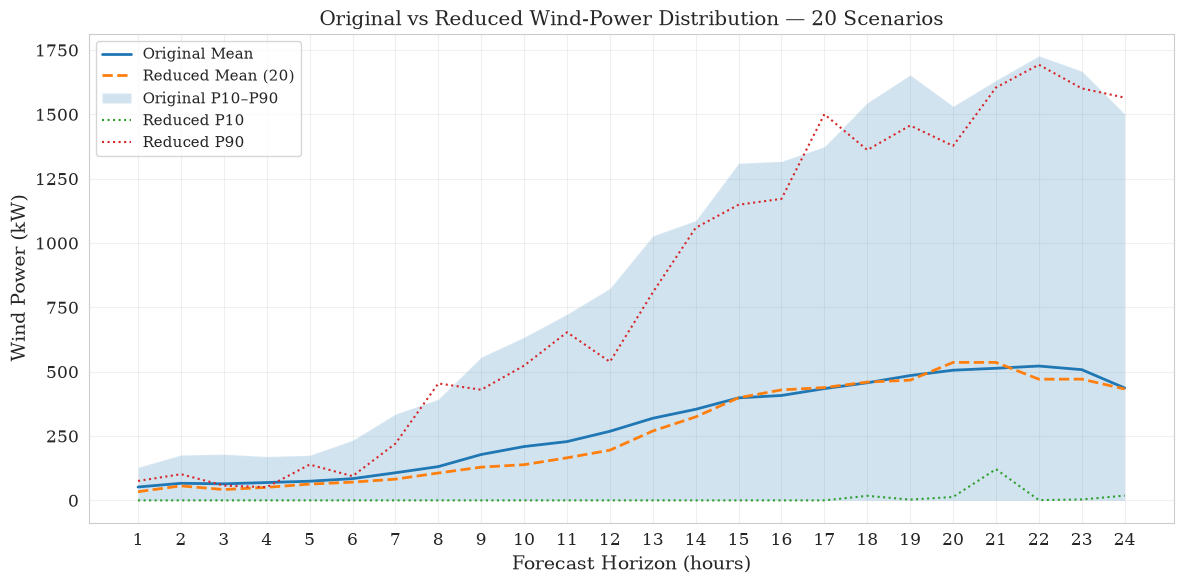

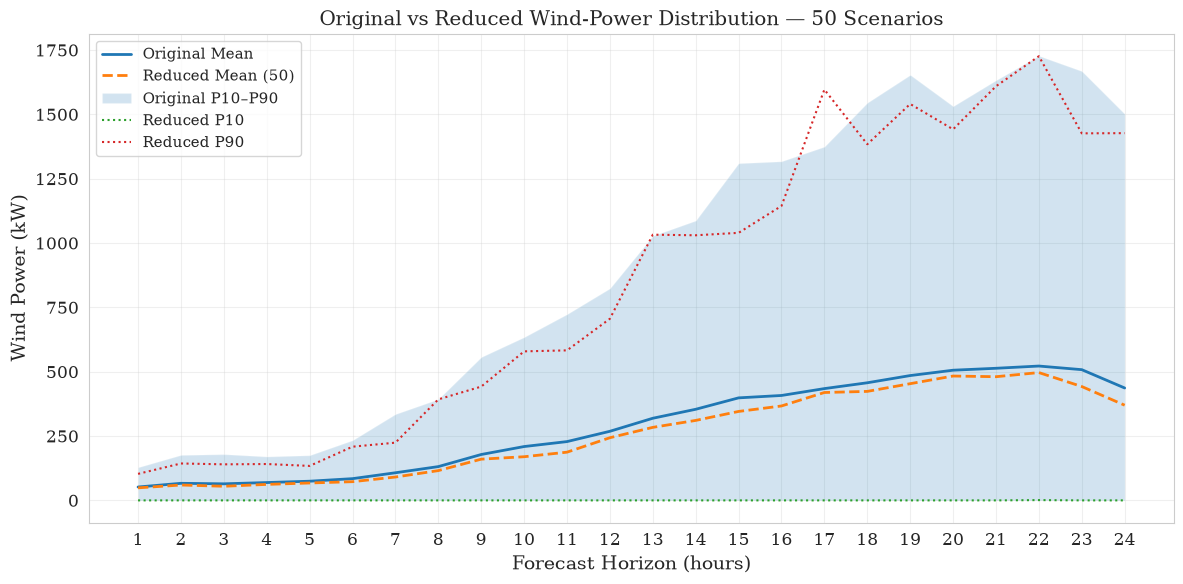

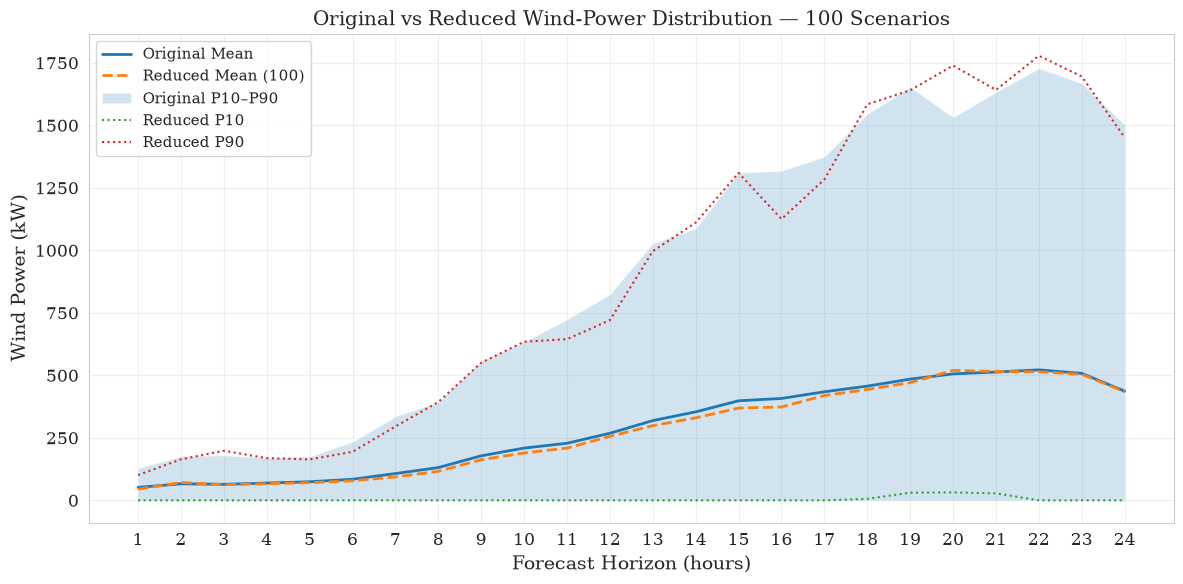

In [139]:
# ============================================================
# VISUAL COMPARISON OF DISTRIBUTIONAL FIDELITY
# ============================================================

hours = np.arange(
    1,
    N_HOURS + 1
)

for k, result in reduced_results.items():

    reduced_scenarios = result["scenarios"]
    probabilities = result["probabilities"]

    reduced_mean = weighted_mean(
        reduced_scenarios,
        probabilities
    )

    reduced_quantiles = (
        weighted_quantiles_by_hour(
            reduced_scenarios,
            probabilities,
            quantiles=[0.10, 0.90]
        )
    )

    plt.figure(figsize=(12, 6))

    plt.plot(
        hours,
        original_hourly_mean,
        linewidth=2,
        label="Original Mean"
    )

    plt.plot(
        hours,
        reduced_mean,
        linewidth=2,
        linestyle="--",
        label=f"Reduced Mean ({k})"
    )

    plt.fill_between(
        hours,
        original_hourly_q10,
        original_hourly_q90,
        alpha=0.20,
        label="Original P10–P90"
    )

    plt.plot(
        hours,
        reduced_quantiles[0.10],
        linestyle=":",
        label="Reduced P10"
    )

    plt.plot(
        hours,
        reduced_quantiles[0.90],
        linestyle=":",
        label="Reduced P90"
    )

    plt.title(
        f"Original vs Reduced Wind-Power Distribution — {k} Scenarios"
    )

    plt.xlabel("Forecast Horizon (hours)")
    plt.ylabel("Wind Power (kW)")
    plt.xticks(hours)

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

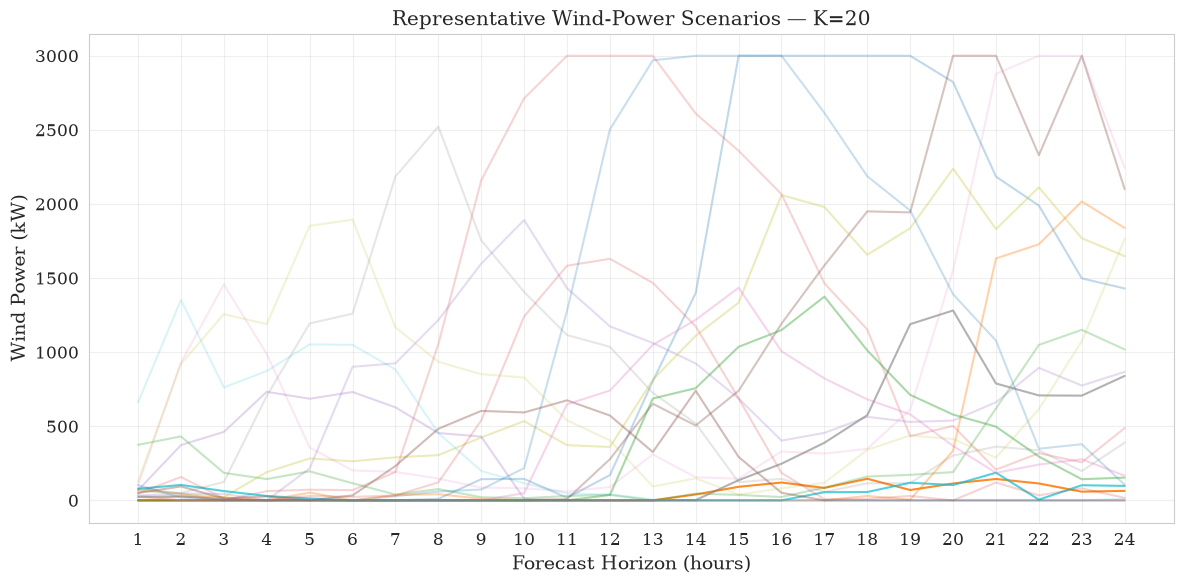

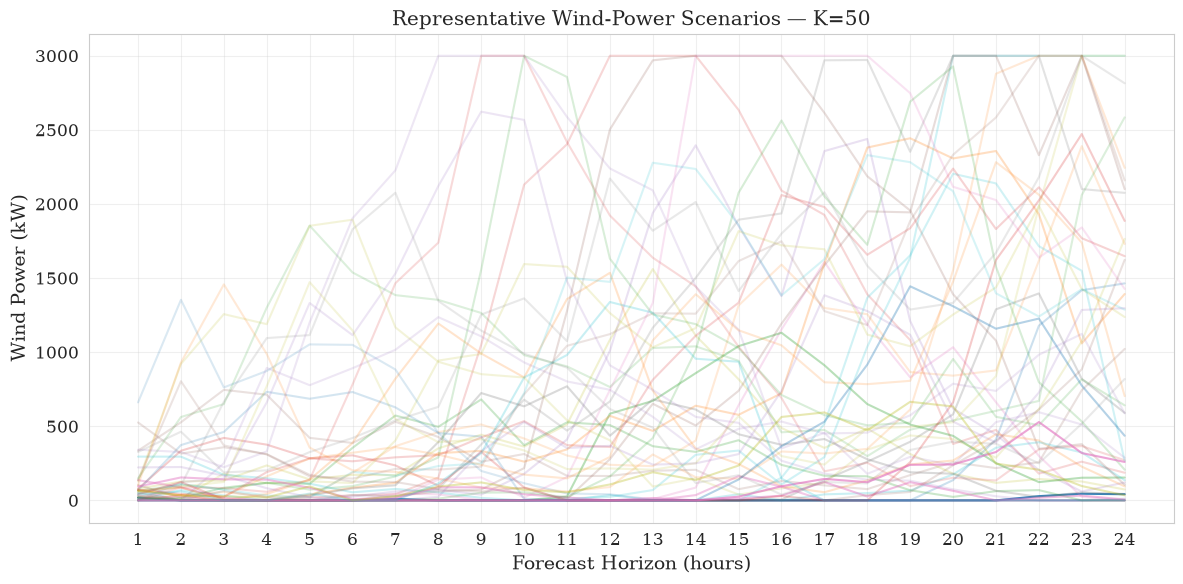

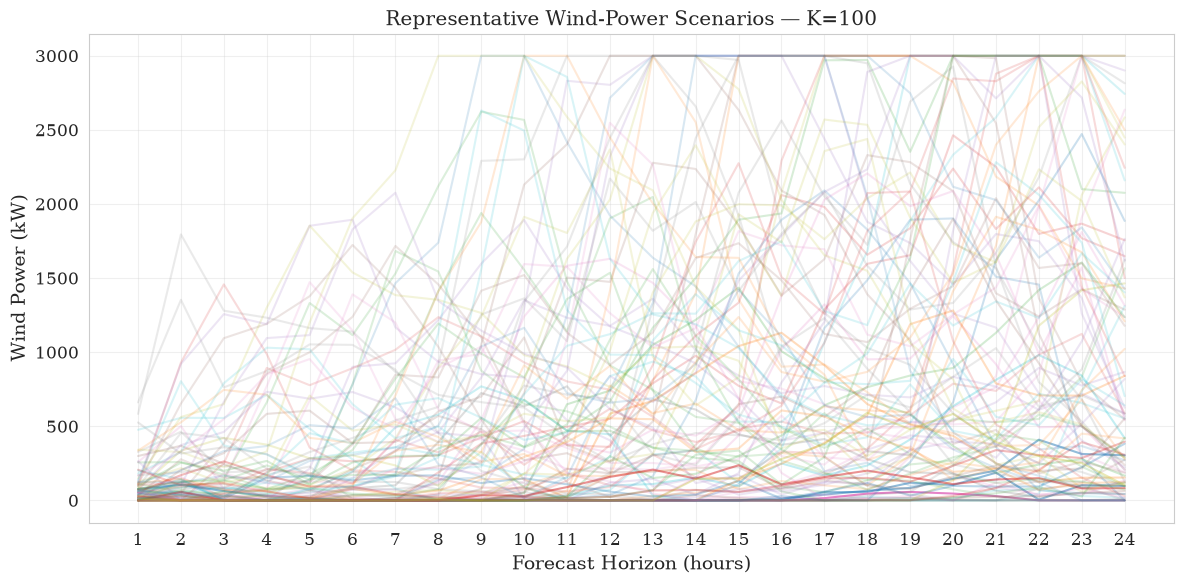

In [140]:
# ============================================================
# REPRESENTATIVE SCENARIO TRAJECTORIES
# ============================================================

for k, result in reduced_results.items():

    plt.figure(figsize=(12, 6))

    for scenario, probability in zip(
        result["scenarios"],
        result["probabilities"]
    ):
        plt.plot(
            hours,
            scenario,
            alpha=min(
                0.15 + probability * 5,
                0.9
            )
        )

    plt.title(
        f"Representative Wind-Power Scenarios — K={k}"
    )

    plt.xlabel("Forecast Horizon (hours)")
    plt.ylabel("Wind Power (kW)")
    plt.xticks(hours)

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [142]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MultipleLocator, StrMethodFormatter


# ============================================================
# SETTINGS
# ============================================================

SCENARIO_COUNT = 100

# OPT_INPUT_DIR and FIGURES_DIR already exist in your notebook.
scenario_file_candidates = [
    OPT_INPUT_DIR / "reduced_wind_power_100_scenarios.csv",
    OPT_INPUT_DIR / "reduced_wind_power_100_scenarios.npy",
]

probability_file_candidates = [
    OPT_INPUT_DIR / "reduced_probabilities_100.npy",
    OPT_INPUT_DIR / "reduced_probabilities_100.csv",
]


# ============================================================
# LOCATE FILES
# ============================================================

def first_existing_file(
    candidates: list[Path],
) -> Path:
    for path in candidates:
        if path.exists():
            return path

    candidate_text = "\n".join(
        str(path) for path in candidates
    )

    raise FileNotFoundError(
        "None of the expected files were found:\n"
        f"{candidate_text}"
    )


scenario_file = first_existing_file(
    scenario_file_candidates
)

probability_file = first_existing_file(
    probability_file_candidates
)

print("Scenario file:", scenario_file)
print("Probability file:", probability_file)


# ============================================================
# LOAD REDUCED SCENARIOS
# ============================================================

if scenario_file.suffix.lower() == ".csv":
    reduced_scenarios = pd.read_csv(
        scenario_file
    ).to_numpy(dtype=float)

elif scenario_file.suffix.lower() == ".npy":
    reduced_scenarios = np.load(
        scenario_file
    ).astype(float)

else:
    raise ValueError(
        f"Unsupported scenario-file format: {scenario_file.suffix}"
    )


if probability_file.suffix.lower() == ".npy":
    probabilities = np.load(
        probability_file
    ).astype(float).reshape(-1)

elif probability_file.suffix.lower() == ".csv":
    probability_df = pd.read_csv(
        probability_file
    )

    probabilities = probability_df.select_dtypes(
        include=[np.number]
    ).iloc[:, 0].to_numpy(dtype=float)

else:
    raise ValueError(
        "Unsupported probability-file format: "
        f"{probability_file.suffix}"
    )


# ============================================================
# HANDLE POSSIBLE CSV ORIENTATION / INDEX COLUMNS
# ============================================================

# Remove a saved index column if the CSV contains 25 columns.
if reduced_scenarios.shape == (
    SCENARIO_COUNT,
    25,
):
    first_column = reduced_scenarios[:, 0]

    expected_index_zero = np.arange(
        SCENARIO_COUNT
    )

    expected_index_one = np.arange(
        1,
        SCENARIO_COUNT + 1,
    )

    if (
        np.allclose(
            first_column,
            expected_index_zero,
        )
        or np.allclose(
            first_column,
            expected_index_one,
        )
    ):
        reduced_scenarios = (
            reduced_scenarios[:, 1:]
        )

# Transpose if saved as 24 × 100.
if reduced_scenarios.shape == (
    24,
    SCENARIO_COUNT,
):
    reduced_scenarios = (
        reduced_scenarios.T
    )


# ============================================================
# VALIDATION
# ============================================================

expected_shape = (
    SCENARIO_COUNT,
    24,
)

if reduced_scenarios.shape != expected_shape:
    raise ValueError(
        f"Expected scenario shape {expected_shape}; "
        f"received {reduced_scenarios.shape}."
    )

if probabilities.shape != (
    SCENARIO_COUNT,
):
    raise ValueError(
        "Expected 100 scenario probabilities; "
        f"received shape {probabilities.shape}."
    )

if not np.isfinite(
    reduced_scenarios
).all():
    raise ValueError(
        "Reduced scenarios contain NaN or infinite values."
    )

if not np.isfinite(
    probabilities
).all():
    raise ValueError(
        "Probabilities contain NaN or infinite values."
    )

if (
    reduced_scenarios < 0
).any():
    raise ValueError(
        "Reduced wind-power scenarios contain negative values."
    )

if (
    probabilities < 0
).any():
    raise ValueError(
        "Scenario probabilities contain negative values."
    )

probability_sum = probabilities.sum()

if not np.isclose(
    probability_sum,
    1.0,
    atol=1e-8,
):
    raise ValueError(
        "Scenario probabilities do not sum to one. "
        f"Sum = {probability_sum:.10f}"
    )

print(
    "Reduced scenarios shape:",
    reduced_scenarios.shape,
)

print(
    "Probability shape:",
    probabilities.shape,
)

print(
    "Probability sum:",
    probabilities.sum(),
)

Scenario file: /Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data/data/optimization_input/reduced_wind_power_100_scenarios.csv
Probability file: /Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data/data/optimization_input/reduced_probabilities_100.npy
Reduced scenarios shape: (100, 24)
Probability shape: (100,)
Probability sum: 1.0


Representative scenario numbers: [17, 1, 54, 61, 37]


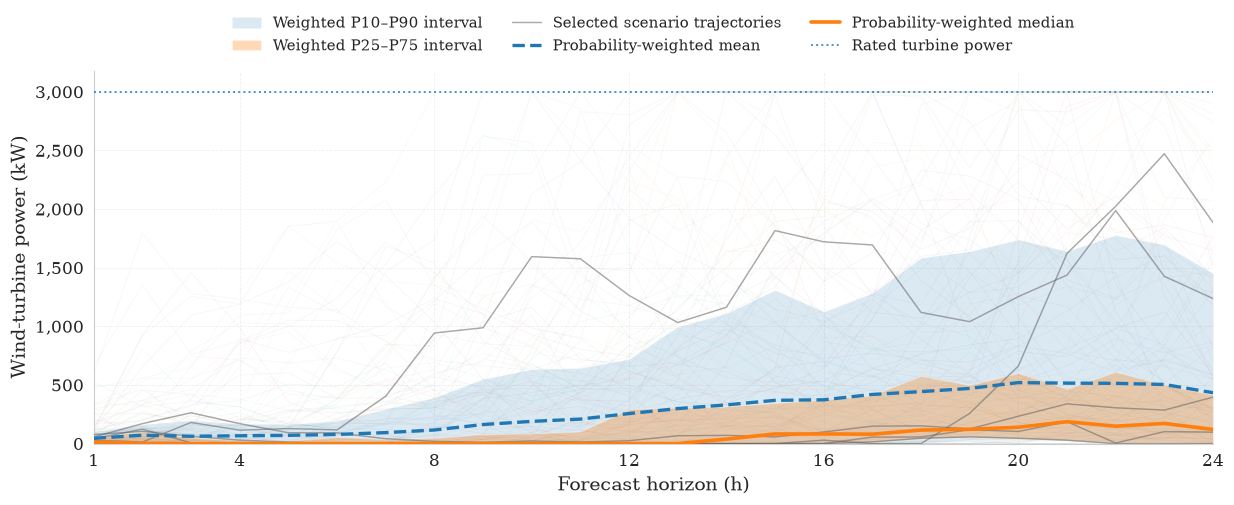

Saved:
/Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data/figures/reducedScenarios100_publication.pdf
/Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data/figures/reducedScenarios100_publication.png


In [146]:
# ============================================================
# WEIGHTED QUANTILE FUNCTIONS
# ============================================================

def weighted_quantile_1d(
    values: np.ndarray,
    weights: np.ndarray,
    quantile: float,
) -> float:
    """Compute one weighted quantile."""

    order = np.argsort(values)

    sorted_values = values[order]
    sorted_weights = weights[order]

    cumulative_weights = np.cumsum(
        sorted_weights
    )

    cumulative_weights /= (
        cumulative_weights[-1]
    )

    return float(
        np.interp(
            quantile,
            cumulative_weights,
            sorted_values,
        )
    )


def weighted_hourly_quantile(
    scenarios: np.ndarray,
    weights: np.ndarray,
    quantile: float,
) -> np.ndarray:
    """Compute a weighted quantile separately for each hour."""

    return np.array(
        [
            weighted_quantile_1d(
                scenarios[:, hour_index],
                weights,
                quantile,
            )
            for hour_index in range(
                scenarios.shape[1]
            )
        ],
        dtype=float,
    )


# ============================================================
# WEIGHTED SUMMARY TRAJECTORIES
# ============================================================

weighted_mean = np.average(
    reduced_scenarios,
    axis=0,
    weights=probabilities,
)

weighted_p10 = weighted_hourly_quantile(
    reduced_scenarios,
    probabilities,
    0.10,
)

weighted_p25 = weighted_hourly_quantile(
    reduced_scenarios,
    probabilities,
    0.25,
)

weighted_p50 = weighted_hourly_quantile(
    reduced_scenarios,
    probabilities,
    0.50,
)

weighted_p75 = weighted_hourly_quantile(
    reduced_scenarios,
    probabilities,
    0.75,
)

weighted_p90 = weighted_hourly_quantile(
    reduced_scenarios,
    probabilities,
    0.90,
)


# ============================================================
# SELECT REPRESENTATIVE TRAJECTORIES BY DAILY ENERGY
# ============================================================

daily_energy_kwh = (
    reduced_scenarios.sum(axis=1)
    * TIME_STEP_HOURS
)

target_quantiles = [
    0.05,
   # 0.20,
    0.25,
    0.50,
    0.75,
  #  0.80,
    0.95,
]

representative_indices: list[int] = []

for quantile in target_quantiles:

    target_daily_energy = (
        weighted_quantile_1d(
            daily_energy_kwh,
            probabilities,
            quantile,
        )
    )

    nearest_candidates = np.argsort(
        np.abs(
            daily_energy_kwh
            - target_daily_energy
        )
    )

    for candidate in nearest_candidates:

        candidate = int(candidate)

        if candidate not in representative_indices:
            representative_indices.append(
                candidate
            )
            break

print(
    "Representative scenario numbers:",
    [
        index + 1
        for index in representative_indices
    ],
)


# ============================================================
# PUBLICATION STYLE
# ============================================================

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 12,
        "axes.labelsize": 14,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 10.5,
        "axes.linewidth": 0.8,
        "savefig.dpi": 600,
    }
)


# ============================================================
# FIGURE 7
# ============================================================

hours = np.arange(
    1,
    25,
)

fig, ax = plt.subplots(
    figsize=(12.5, 5.8)
)


# All 100 scenarios as a subtle background.
for scenario_index in range(
    SCENARIO_COUNT
):
    ax.plot(
        hours,
        reduced_scenarios[
            scenario_index
        ],
        linewidth=0.55,
        alpha=0.06,
        zorder=1,
    )


# Weighted outer interval.
ax.fill_between(
    hours,
    weighted_p10,
    weighted_p90,
    alpha=0.16,
    label="Weighted P10–P90 interval",
    zorder=2,
)


# Weighted central interval.
ax.fill_between(
    hours,
    weighted_p25,
    weighted_p75,
    alpha=0.30,
    label="Weighted P25–P75 interval",
    zorder=3,
)


# Seven representative trajectories.
for position, scenario_index in enumerate(representative_indices):
    ax.plot(
        hours,
        reduced_scenarios[scenario_index],
        linewidth=1.05,
        alpha=0.55,
        color="0.40",
        label=(
            "Selected scenario trajectories"
            if position == 0
            else None
        ),
        zorder=4,
    )


# Probability-weighted mean.
ax.plot(
    hours,
    weighted_mean,
    linewidth=2.4,
    linestyle="--",
    label="Probability-weighted mean",
    zorder=6,
)


# Probability-weighted median.
ax.plot(
    hours,
    weighted_p50,
    linewidth=2.6,
    label="Probability-weighted median",
    zorder=7,
)


# Rated turbine power.
ax.axhline(
    y=RATED_POWER_KW,
    linestyle=":",
    linewidth=1.4,
    alpha=0.80,
    label="Rated turbine power",
    zorder=5,
)


# ============================================================
# FORMATTING
# ============================================================

ax.set_xlabel(
    "Forecast horizon (h)"
)

ax.set_ylabel(
    "Wind-turbine power (kW)"
)

ax.set_xlim(
    1,
    24,
)

ax.set_ylim(
    0,
    RATED_POWER_KW * 1.06,
)

ax.set_xticks(
    [1, 4, 8, 12, 16, 20, 24]
)

ax.yaxis.set_major_locator(
    MultipleLocator(500)
)

ax.yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.55,
    alpha=0.32,
)

ax.spines[
    "top"
].set_visible(False)

ax.spines[
    "right"
].set_visible(False)

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=3,
    frameon=False,
)

fig.tight_layout(
    rect=[0, 0, 1, 0.90]
)


# ============================================================
# SAVE
# ============================================================

pdf_path = (
    FIGURES_DIR
    / "reducedScenarios100_publication.pdf"
)

png_path = (
    FIGURES_DIR
    / "reducedScenarios100_publication.png"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
)

plt.show()

print("Saved:")
print(pdf_path)
print(png_path)

In [147]:
# ============================================================
# SELECT FINAL SCENARIO SET
# ============================================================

SELECTED_K = 50  # Change only after reviewing fidelity metrics

selected_result = reduced_results[
    SELECTED_K
]

reduced_wind_power_kw = (
    selected_result["scenarios"]
)

reduced_scenario_probabilities = (
    selected_result["probabilities"]
)

reduced_wind_energy_kwh = (
    reduced_wind_power_kw
    * TIME_STEP_HOURS
)


print(
    "Reduced power shape:",
    reduced_wind_power_kw.shape
)

print(
    "Reduced energy shape:",
    reduced_wind_energy_kwh.shape
)

print(
    "Probability sum:",
    reduced_scenario_probabilities.sum()
)

Reduced power shape: (50, 24)
Reduced energy shape: (50, 24)
Probability sum: 1.0


In [148]:
# ============================================================
# LONG-FORM OPTIMIZATION INPUT
# ============================================================

optimization_rows = []

for scenario_id in range(
    SELECTED_K
):

    probability = (
        reduced_scenario_probabilities[
            scenario_id
        ]
    )

    for hour in range(
        N_HOURS
    ):

        optimization_rows.append({
            "scenario_id":
                scenario_id + 1,

            "hour":
                hour + 1,

            "probability":
                probability,

            "wind_power_kw":
                reduced_wind_power_kw[
                    scenario_id,
                    hour
                ],

            "wind_energy_kwh":
                reduced_wind_energy_kwh[
                    scenario_id,
                    hour
                ]
        })


optimization_wind_scenarios_df = pd.DataFrame(
    optimization_rows
)


display(
    optimization_wind_scenarios_df.head(30)
)

,scenario_id,hour,probability,wind_power_kw,wind_energy_kwh
0,1,1,0.289,18.522930,18.522930
1,1,2,0.289,0.000000,0.000000
2,1,3,0.289,0.000000,0.000000
3,1,4,0.289,0.000000,0.000000
4,1,5,0.289,0.000000,0.000000
5,1,6,0.289,0.000000,0.000000
6,1,7,0.289,9.816399,9.816399
7,1,8,0.289,0.000000,0.000000
8,1,9,0.289,0.000000,0.000000
9,1,10,0.289,0.000000,0.000000


In [149]:
# ============================================================
# SAVE ALL CANDIDATE REDUCTIONS
# ============================================================

for k, result in reduced_results.items():

    np.save(
        f"reduced_wind_power_{k}_scenarios.npy",
        result["scenarios"]
    )

    np.save(
        f"reduced_probabilities_{k}.npy",
        result["probabilities"]
    )

    pd.DataFrame(
        result["scenarios"],
        columns=[
            f"hour_{hour}"
            for hour in range(
                1,
                N_HOURS + 1
            )
        ]
    ).to_csv(
        f"reduced_wind_power_{k}_scenarios.csv",
        index=False
    )


reduction_evaluation_df.to_csv(
    "scenario_reduction_fidelity.csv",
    index=False
)


optimization_wind_scenarios_df.to_csv(
    "optimization_ready_wind_scenarios.csv",
    index=False
)

print("Scenario-reduction outputs saved.")

Scenario-reduction outputs saved.
